# Week 2 — Training a Neural Network from Scratch

**CSS371: Natural Language Processing**  
**Implementation:** NumPy only for the core models; no `torch.nn`, autograd, or optimizer


## Learning objectives

By the end of this lesson, students should be able to:

1. define supervised binary classification and identify $X$, $y$, parameters, predictions, and loss;
2. implement a neuron using a weighted sum and sigmoid activation;
3. derive binary cross-entropy gradients for logistic regression;
4. implement a two-layer neural network with ReLU from scratch;
5. explain forward propagation, backpropagation, and gradient descent as separate operations;
6. verify an analytical gradient with finite differences;
7. evaluate predictions with accuracy, precision, recall, F1, and a confusion matrix;
8. construct Bag-of-Words features without data leakage;
9. train a mock sentence classifier using the same from-scratch machinery;
10. identify limitations of small synthetic data and order-insensitive text features.


## 1. Problem definition: supervised binary classification

We observe a dataset

$$\mathcal{D}=\{(\mathbf{x}^{(i)},y^{(i)})\}_{i=1}^{N},$$

where:

- $N$ is the number of examples;
- $\mathbf{x}^{(i)}\in\mathbb{R}^{D}$ is a vector of $D$ input features;
- $y^{(i)}\in\{0,1\}$ is the correct class label.

The model produces a probability

$$\hat y^{(i)}=P(y=1\mid\mathbf{x}^{(i)};\theta),$$

where $\theta$ denotes every trainable parameter. A threshold converts probability into a class:

$$\tilde y^{(i)}=\begin{cases}1 & \hat y^{(i)}\ge 0.5\\0 & \hat y^{(i)}<0.5.\end{cases}$$

### Training versus inference

- **Training:** predictions → loss → gradients → parameter update.
- **Inference:** predictions only; labels and parameter updates are not required.

The threshold is a decision policy, not part of gradient-based training. Training operates on continuous probabilities.


In [1]:
import sys
import random
import numpy as np
import re
from collections import Counter
from IPython.display import SVG, display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | seed={SEED}")


Python 3.13.15 | NumPy 2.1.3 | seed=42


## 2. Mock classification data

Our first dataset contains two numerical features. Class 0 is sampled near $(-1,-1)$ and class 1 near $(1,1)$. The classes overlap slightly, so the task resembles a real classification problem more than perfectly separable points would.

The feature matrix and label vector have shapes

$$X\in\mathbb{R}^{N\times D},\qquad y\in\{0,1\}^{N\times 1}.$$

We shuffle before splitting so that both partitions contain both labels. The validation set is not used to calculate gradients.


In [2]:
def make_blob_data(n_per_class=100, noise=0.75, seed=42):
    rng = np.random.default_rng(seed)
    class_0 = rng.normal(loc=(-1.0, -1.0), scale=noise, size=(n_per_class, 2))
    class_1 = rng.normal(loc=(1.0, 1.0), scale=noise, size=(n_per_class, 2))
    X = np.vstack([class_0, class_1])
    y = np.vstack([np.zeros((n_per_class, 1)), np.ones((n_per_class, 1))])
    order = rng.permutation(len(X))
    return X[order], y[order]

X, y = make_blob_data()
split = int(0.8 * len(X))
X_train, X_valid = X[:split], X[split:]
y_train, y_valid = y[:split], y[split:]

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_valid:", X_valid.shape, "y_valid:", y_valid.shape)
print("training class counts:", np.bincount(y_train.astype(int).ravel()))
assert X_train.shape == (160, 2)
assert y_train.shape == (160, 1)


X_train: (160, 2) y_train: (160, 1)
X_valid: (40, 2) y_valid: (40, 1)
training class counts: [83 77]


### Visualizing the dataset in feature space

Each point represents one example $\mathbf{x}^{(i)}=(x_1^{(i)},x_2^{(i)})$. Color indicates the target class. Filled circles are training examples; outlined circles are validation examples that are not used to calculate gradients.

Before running the cell, predict where a linear decision boundary could separate the two groups and identify the region where mistakes are most likely.


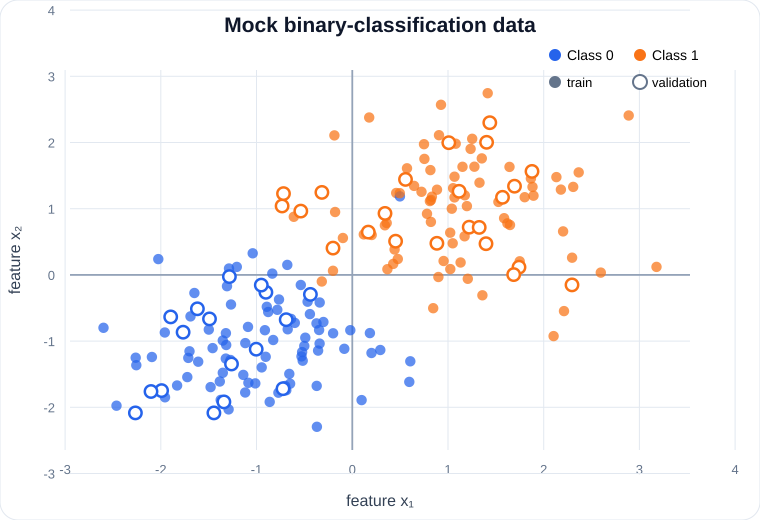

In [3]:
def scatter_svg(X_train, y_train, X_valid, y_valid, width=760, height=520):
    margin = 70
    all_X = np.vstack([X_train, X_valid])
    x_min, x_max = all_X[:, 0].min() - 0.35, all_X[:, 0].max() + 0.35
    y_min, y_max = all_X[:, 1].min() - 0.35, all_X[:, 1].max() + 0.35
    sx = lambda value: margin + (value - x_min) / (x_max - x_min) * (width - 2 * margin)
    sy = lambda value: height - margin - (value - y_min) / (y_max - y_min) * (height - 2 * margin)
    colors = {0: '#2563eb', 1: '#f97316'}

    elements = [
        f"<svg xmlns='http://www.w3.org/2000/svg' width='{width}' height='{height}' viewBox='0 0 {width} {height}'>",
        "<rect width='100%' height='100%' rx='18' fill='white' stroke='#e2e8f0'/>",
        f"<text x='{width/2}' y='32' text-anchor='middle' font-family='Arial' font-size='21' font-weight='bold' fill='#0f172a'>Mock binary-classification data</text>",
    ]
    # Grid and numeric ticks
    for value in range(int(np.floor(x_min)), int(np.ceil(x_max)) + 1):
        x = sx(value)
        elements.append(f"<line x1='{x:.1f}' y1='{margin}' x2='{x:.1f}' y2='{height-margin}' stroke='#e2e8f0'/>")
        elements.append(f"<text x='{x:.1f}' y='{height-margin+24}' text-anchor='middle' font-family='Arial' font-size='13' fill='#64748b'>{value}</text>")
    for value in range(int(np.floor(y_min)), int(np.ceil(y_max)) + 1):
        y = sy(value)
        elements.append(f"<line x1='{margin}' y1='{y:.1f}' x2='{width-margin}' y2='{y:.1f}' stroke='#e2e8f0'/>")
        elements.append(f"<text x='{margin-15}' y='{y+5:.1f}' text-anchor='end' font-family='Arial' font-size='13' fill='#64748b'>{value}</text>")
    # Axes through the origin when it lies in the visible range
    elements.append(f"<line x1='{sx(0):.1f}' y1='{margin}' x2='{sx(0):.1f}' y2='{height-margin}' stroke='#94a3b8' stroke-width='1.8'/>")
    elements.append(f"<line x1='{margin}' y1='{sy(0):.1f}' x2='{width-margin}' y2='{sy(0):.1f}' stroke='#94a3b8' stroke-width='1.8'/>")
    # Training points: filled; validation points: white center with colored outline
    for features, label in zip(X_train, y_train.astype(int).ravel()):
        elements.append(f"<circle cx='{sx(features[0]):.1f}' cy='{sy(features[1]):.1f}' r='5.2' fill='{colors[label]}' fill-opacity='0.72'/>")
    for features, label in zip(X_valid, y_valid.astype(int).ravel()):
        elements.append(f"<circle cx='{sx(features[0]):.1f}' cy='{sy(features[1]):.1f}' r='6.2' fill='white' stroke='{colors[label]}' stroke-width='2.5'/>")
    elements += [
        f"<text x='{width/2}' y='{height-14}' text-anchor='middle' font-family='Arial' font-size='16' fill='#334155'>feature x₁</text>",
        f"<text x='20' y='{height/2}' text-anchor='middle' font-family='Arial' font-size='16' fill='#334155' transform='rotate(-90 20 {height/2})'>feature x₂</text>",
        f"<circle cx='{width-205}' cy='55' r='6' fill='{colors[0]}'/><text x='{width-193}' y='60' font-family='Arial' font-size='14'>Class 0</text>",
        f"<circle cx='{width-120}' cy='55' r='6' fill='{colors[1]}'/><text x='{width-108}' y='60' font-family='Arial' font-size='14'>Class 1</text>",
        f"<circle cx='{width-205}' cy='82' r='6' fill='#64748b'/><text x='{width-193}' y='87' font-family='Arial' font-size='13'>train</text>",
        f"<circle cx='{width-120}' cy='82' r='7' fill='white' stroke='#64748b' stroke-width='2'/><text x='{width-108}' y='87' font-family='Arial' font-size='13'>validation</text>",
        "</svg>",
    ]
    return ''.join(elements)

display(SVG(scatter_svg(X_train, y_train, X_valid, y_valid)))


In [4]:
X_train

array([[-1.28739049,  0.09608322],
       [-0.34642842, -0.83230334],
       [ 1.64259549,  1.63136505],
       [ 0.89963278, -0.03117186],
       [-0.44255937, -0.5926343 ],
       [ 0.3675773 ,  0.0858902 ],
       [ 1.64787101,  0.75360608],
       [-0.30132024, -0.71128678],
       [ 0.6062357 , -1.30481126],
       [-1.3744717 , -1.88870782],
       [-0.20169466,  0.06126459],
       [ 3.17880038,  0.12132503],
       [-1.29235735, -2.03251461],
       [ 1.80135367,  1.17465852],
       [ 2.29652323,  0.25985719],
       [ 0.35249105,  0.88935349],
       [ 0.5963523 , -1.61604001],
       [ 1.89335721,  1.19706192],
       [ 2.20319077,  0.65672543],
       [-0.1861958 ,  2.10696179],
       [-0.49081483, -0.9493157 ],
       [ 0.34138572,  0.74940742],
       [-0.52363679, -1.16666702],
       [-1.49913228, -0.82587901],
       [-1.32043948, -0.88109523],
       [ 1.15172964,  1.63328889],
       [ 1.35365389,  1.75953686],
       [ 0.20318919,  0.60292043],
       [-0.78316045,

In [5]:
y_train

array([[0.],
       [0.],
       [1.],
       [1.],
       [0.],
       [1.],
       [1.],
       [0.],
       [0.],
       [0.],
       [1.],
       [1.],
       [0.],
       [1.],
       [1.],
       [1.],
       [0.],
       [1.],
       [1.],
       [1.],
       [0.],
       [1.],
       [0.],
       [0.],
       [0.],
       [1.],
       [1.],
       [1.],
       [0.],
       [0.],
       [1.],
       [1.],
       [0.],
       [1.],
       [0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [1.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [1.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [1.],
       [0.],
       [1.],

## 3. A single artificial neuron

A neuron first calculates a weighted sum called a **logit**:

$$z=\mathbf{x}^{\top}\mathbf{w}+b=\sum_{j=1}^{D}x_jw_j+b.$$

- $w_j$ controls how feature $j$ affects the output.
- $b$ shifts the decision boundary independently of the input.
- $z$ can be any real number and is not yet a probability.

For binary classification, the sigmoid activation maps the logit into $(0,1)$:

$$\sigma(z)=\frac{1}{1+e^{-z}}.$$

The derivative is

$$\sigma'(z)=\sigma(z)(1-\sigma(z)).$$

A numerically stable implementation treats positive and negative logits separately to avoid overflow in $e^{-z}$.


In [6]:
def sigmoid(z):
    z = np.asarray(z, dtype=float)
    output = np.empty_like(z)
    positive = z >= 0
    output[positive] = 1.0 / (1.0 + np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    output[~positive] = exp_z / (1.0 + exp_z)
    return output

test_logits = np.array([-1000.0, -2.0, 0.0, 2.0, 1000.0])
print("logits:       ", test_logits)
print("probabilities:", sigmoid(test_logits))
assert np.all((sigmoid(test_logits) >= 0) & (sigmoid(test_logits) <= 1))
assert np.isclose(sigmoid(np.array([0.0]))[0], 0.5)


logits:        [-1000.    -2.     0.     2.  1000.]
probabilities: [0.         0.11920292 0.5        0.88079708 1.        ]


## 4. Binary cross-entropy loss

For one example, binary cross-entropy (BCE) is

$$\ell(y,\hat y)=-\left[y\log(\hat y)+(1-y)\log(1-\hat y)\right].$$

For a batch of $N$ examples:

$$L=-\frac{1}{N}\sum_{i=1}^{N}\left[y^{(i)}\log(\hat y^{(i)})+(1-y^{(i)})\log(1-\hat y^{(i)})\right].$$

Interpretation:

- if $y=1$, the loss becomes $-\log(\hat y)$ and strongly penalizes a small predicted probability;
- if $y=0$, it becomes $-\log(1-\hat y)$;
- confident wrong predictions receive a large penalty;
- perfect probabilities would give loss 0.

In code, clip probabilities away from exactly 0 and 1 before taking logarithms.


In [7]:
def binary_cross_entropy(y_true, y_probability, epsilon=1e-12):
    p = np.clip(y_probability, epsilon, 1.0 - epsilon)
    return -np.mean(y_true * np.log(p) + (1.0 - y_true) * np.log(1.0 - p))

cases = [(1, 0.99), (1, 0.60), (1, 0.10), (0, 0.01), (0, 0.90)]
for label, probability in cases:
    loss = binary_cross_entropy(np.array([[label]]), np.array([[probability]]))
    print(f"label={label}, probability(class 1)={probability:.2f}, loss={loss:.4f}")


label=1, probability(class 1)=0.99, loss=0.0101
label=1, probability(class 1)=0.60, loss=0.5108
label=1, probability(class 1)=0.10, loss=2.3026
label=0, probability(class 1)=0.01, loss=0.0101
label=0, probability(class 1)=0.90, loss=2.3026


## 5. Model 1 — Logistic regression from scratch

Despite its name, logistic regression is a binary classifier consisting of one sigmoid neuron:

$$Z=XW+b,\qquad \hat Y=\sigma(Z).$$

![Logistic regression represented as a one-neuron network](assets/logistic_regression_network.svg)

*Each feature contributes through its weight to the logit $z$. Sigmoid converts the logit into $\hat y=P(y=1\mid x)$; the threshold is used only when a discrete class is required.*

Shapes:

| Quantity | Shape |
|---|---|
| $X$ | $(N,D)$ |
| $W$ | $(D,1)$ |
| $b$ | scalar or $(1,)$ |
| $Z,\hat Y,Y$ | $(N,1)$ |

### Detailed proof of the gradients

We first derive the result for **one training example**, then extend it to a batch. Let

$$z=\mathbf{x}^{\top}\mathbf{w}+b,\qquad p=\hat y=\sigma(z),$$

and define the one-example BCE loss

$$\ell(y,p)=-y\log p-(1-y)\log(1-p).$$

#### Step A — Differentiate the sigmoid

Starting from $p=\sigma(z)=(1+e^{-z})^{-1}$,

$$\frac{dp}{dz}
=-(1+e^{-z})^{-2}(-e^{-z})
=\frac{e^{-z}}{(1+e^{-z})^2}.$$

Because $p=1/(1+e^{-z})$ and $1-p=e^{-z}/(1+e^{-z})$,

$$\boxed{\frac{dp}{dz}=p(1-p)}.$$

#### Step B — Differentiate BCE with respect to the probability

Treat $y$ as a constant label and differentiate with respect to $p$:

$$\frac{\partial \ell}{\partial p}
=-y\frac{1}{p}-(1-y)\left(-\frac{1}{1-p}\right)
=-\frac{y}{p}+\frac{1-y}{1-p}.$$

Put the two fractions over the common denominator $p(1-p)$:

$$\frac{\partial \ell}{\partial p}
=\frac{-y(1-p)+(1-y)p}{p(1-p)}
=\frac{-y+yp+p-yp}{p(1-p)}
=\boxed{\frac{p-y}{p(1-p)}}.$$

#### Step C — Apply the chain rule through sigmoid

The loss depends on $z$ only through $p=\sigma(z)$, so

$$\frac{\partial \ell}{\partial z}
=\frac{\partial \ell}{\partial p}\frac{dp}{dz}
=\frac{p-y}{p(1-p)}\,p(1-p)
=\boxed{p-y}.$$

The sigmoid derivative cancels the denominator created by BCE. This is why the combined gradient is unusually simple. It also has an intuitive sign:

- if $p>y$, the model predicts too high and $\partial\ell/\partial z>0$, so Gradient Descent decreases $z$;
- if $p<y$, the model predicts too low and the gradient is negative, so Gradient Descent increases $z$;
- if $p=y$, the output-level gradient is zero.

#### Step D — Differentiate the logit with respect to each parameter

Expand the logit:

$$z=x_1w_1+x_2w_2+\cdots+x_Dw_D+b.$$

Therefore, for parameter $w_j$,

$$\frac{\partial z}{\partial w_j}=x_j,\qquad\frac{\partial z}{\partial b}=1.$$

Using the chain rule again,

$$\boxed{\frac{\partial \ell}{\partial w_j}=(p-y)x_j},\qquad
\boxed{\frac{\partial \ell}{\partial b}=p-y}.$$

In vector form for one example,

$$\boxed{\nabla_{\mathbf{w}}\ell=\mathbf{x}(p-y)}.$$

#### Step E — Extend from one example to a mean batch loss

For $N$ examples, $L=(1/N)\sum_i\ell^{(i)}$. Hence

$$\frac{\partial L}{\partial z_i}=\frac{p_i-y_i}{N}.$$

Stack these values into $dZ=(\hat Y-Y)/N$ with shape $(N,1)$. Summing the contribution of every example gives

$$\frac{\partial L}{\partial w_j}
=\frac{1}{N}\sum_{i=1}^{N}x_{ij}(p_i-y_i).$$

All $D$ weight derivatives can be computed simultaneously by matrix multiplication:

$$\boxed{\frac{\partial L}{\partial W}=X^{\top}dZ
=X^{\top}\frac{\hat Y-Y}{N}}.$$

The bias is broadcast to every example, so its gradient is the sum across batch rows:

$$\boxed{\frac{\partial L}{\partial b}=\sum_{i=1}^{N}dZ_i
=\frac{1}{N}\sum_{i=1}^{N}(p_i-y_i)}.$$

#### Shape verification

$$X^{\top}:(D,N),\qquad dZ:(N,1),$$

so

$$X^{\top}dZ:(D,N)(N,1)=(D,1),$$

which exactly matches the shape of $W$. Likewise, summing $dZ$ over its $N$ rows produces one bias gradient.

> If BCE were **summed** rather than averaged, the factor $1/N$ would disappear. The code and derivation must use the same reduction convention.

### Why update in the negative-gradient direction?

Let all parameters be collected in $\theta$. For a small change $\Delta\theta$, the first-order Taylor approximation is

$$L(\theta+\Delta\theta)\approx L(\theta)+\nabla L(\theta)^{\top}\Delta\theta.$$

Choose $\Delta\theta=-\eta\nabla L(\theta)$ with $\eta>0$. Then

$$L(\theta+\Delta\theta)-L(\theta)
\approx-\eta\nabla L(\theta)^{\top}\nabla L(\theta)
=-\eta\|\nabla L(\theta)\|_2^2\le0.$$

Thus, for a sufficiently small learning rate, the negative gradient gives a local decrease. The actual parameter updates are

$$\boxed{W\leftarrow W-\eta\frac{\partial L}{\partial W}},\qquad
\boxed{b\leftarrow b-\eta\frac{\partial L}{\partial b}}.$$

The Taylor argument is local; if $\eta$ is too large, higher-order curvature terms can cause overshooting or divergence.


### Worked numerical check of the proof

The following one-example calculation evaluates $p-y$, forms $dW=\mathbf{x}(p-y)$ and $db=p-y$, and compares them with finite-difference derivatives. Agreement provides numerical evidence that the derived expressions were implemented correctly.


In [8]:
x_one = np.array([[2.0, -1.0]])
y_one = np.array([[1.0]])
W_one = np.array([[0.30], [-0.20]])
b_one = np.array([0.10])

z_one = x_one @ W_one + b_one
p_one = sigmoid(z_one)
dZ_one = p_one - y_one
dW_one = x_one.T @ dZ_one
db_one = np.sum(dZ_one, axis=0)

def one_example_loss(W, b):
    probability = sigmoid(x_one @ W + b)
    return binary_cross_entropy(y_one, probability)

epsilon = 1e-5
numeric_dW = np.zeros_like(W_one)
for row in range(len(W_one)):
    W_plus, W_minus = W_one.copy(), W_one.copy()
    W_plus[row, 0] += epsilon
    W_minus[row, 0] -= epsilon
    numeric_dW[row, 0] = (one_example_loss(W_plus, b_one) - one_example_loss(W_minus, b_one)) / (2 * epsilon)
numeric_db = (one_example_loss(W_one, b_one + epsilon) - one_example_loss(W_one, b_one - epsilon)) / (2 * epsilon)

print(f"z={z_one.item():.6f}, p={p_one.item():.6f}, y={y_one.item():.0f}, p-y={dZ_one.item():.6f}")
print("analytical dW:", dW_one.ravel())
print("numerical  dW:", numeric_dW.ravel())
print(f"analytical db: {db_one.item():.8f}")
print(f"numerical  db: {numeric_db:.8f}")
assert np.allclose(dW_one, numeric_dW, atol=1e-8)
assert np.allclose(db_one, numeric_db, atol=1e-8)


z=0.900000, p=0.710950, y=1, p-y=-0.289050
analytical dW: [-0.57810099  0.2890505 ]
numerical  dW: [-0.57810099  0.2890505 ]
analytical db: -0.28905050
numerical  db: -0.28905050


In [9]:
def logistic_forward(X, parameters):
    logits = X @ parameters["W"] + parameters["b"]
    probabilities = sigmoid(logits)
    return probabilities, {"X": X, "probabilities": probabilities}

def logistic_backward(y_true, parameters, cache):
    X, probabilities = cache["X"], cache["probabilities"]
    n = len(X)
    d_logits = (probabilities - y_true) / n
    return {
        "W": X.T @ d_logits,
        "b": np.sum(d_logits, axis=0),
    }

def update_parameters(parameters, gradients, learning_rate):
    for name in parameters:
        parameters[name] -= learning_rate * gradients[name]

def predict_binary(probabilities, threshold=0.5):
    return (probabilities >= threshold).astype(int)

logistic_parameters = {
    "W": np.zeros((X_train.shape[1], 1)),
    "b": np.zeros((1,)),
}

logistic_history = []
for epoch in range(401):
    train_probability, cache = logistic_forward(X_train, logistic_parameters)
    loss = binary_cross_entropy(y_train, train_probability)
    gradients = logistic_backward(y_train, logistic_parameters, cache)
    update_parameters(logistic_parameters, gradients, learning_rate=0.1)
    logistic_history.append(loss)
    if epoch % 100 == 0:
        train_accuracy = np.mean(predict_binary(train_probability) == y_train)
        print(f"epoch={epoch:3d} loss={loss:.4f} train_accuracy={train_accuracy:.3f}")

valid_probability, _ = logistic_forward(X_valid, logistic_parameters)
valid_prediction = predict_binary(valid_probability)
print("parameters:", logistic_parameters)
print("validation accuracy:", np.mean(valid_prediction == y_valid))
assert logistic_history[-1] < logistic_history[0]


epoch=  0 loss=0.6931 train_accuracy=0.481
epoch=100 loss=0.1308 train_accuracy=0.981
epoch=200 loss=0.1011 train_accuracy=0.981
epoch=300 loss=0.0900 train_accuracy=0.981
epoch=400 loss=0.0841 train_accuracy=0.981
parameters: {'W': array([[2.14335562],
       [2.14422805]]), 'b': array([-0.00166673])}
validation accuracy: 1.0


### The training loop, line by line

1. **Forward:** calculate probabilities using the current parameters.
2. **Loss:** summarize prediction error into one scalar.
3. **Backward:** calculate how each parameter contributed to that scalar.
4. **Update:** subtract learning rate times gradient.
5. **Repeat:** the next forward pass uses the updated parameters.

Unlike PyTorch, NumPy does not remember a computation graph. Every derivative in `logistic_backward` was derived and implemented manually.

### Decision boundary

At threshold 0.5, sigmoid predicts class 1 whenever $z\ge 0$. Therefore the boundary satisfies

$$x_1w_1+x_2w_2+b=0.$$

This is a straight line in two dimensions. Logistic regression cannot create a curved or disconnected boundary without nonlinear feature engineering.


## 6. Gradient checking

A small sign, transpose, or averaging error can make backpropagation silently wrong. We verify one analytical gradient using the centered finite difference:

$$\frac{\partial L}{\partial\theta_j}\approx
\frac{L(\theta_j+\epsilon)-L(\theta_j-\epsilon)}{2\epsilon}.$$

Define relative error

$$\text{relative error}=
\frac{|g_{analytic}-g_{numeric}|}{\max(1,|g_{analytic}|,|g_{numeric}|)}.$$

Gradient checking is expensive because it requires two forward passes per checked parameter. Use it for debugging small models, not for ordinary training.


In [10]:
check_parameters = {"W": np.array([[0.2], [-0.1]]), "b": np.array([0.05])}
check_X, check_y = X_train[:8], y_train[:8]
check_probability, check_cache = logistic_forward(check_X, check_parameters)
analytical = logistic_backward(check_y, check_parameters, check_cache)

epsilon = 1e-5
original = check_parameters["W"][0, 0]
check_parameters["W"][0, 0] = original + epsilon
loss_plus = binary_cross_entropy(check_y, logistic_forward(check_X, check_parameters)[0])
check_parameters["W"][0, 0] = original - epsilon
loss_minus = binary_cross_entropy(check_y, logistic_forward(check_X, check_parameters)[0])
check_parameters["W"][0, 0] = original

numerical = (loss_plus - loss_minus) / (2 * epsilon)
analytic = analytical["W"][0, 0]
relative_error = abs(analytic - numerical) / max(1.0, abs(analytic), abs(numerical))
print("analytical gradient:", analytic)
print("numerical gradient: ", numerical)
print("relative error:     ", relative_error)
assert relative_error < 1e-7


analytical gradient: -0.3919132087644769
numerical gradient:  -0.3919132087693011
relative error:      4.8241965977524615e-12


## 7. Why add a hidden layer?

A neural network becomes more expressive by alternating affine transformations and nonlinear activations. A two-layer binary classifier is

$$Z_1=XW_1+b_1,$$
$$A_1=\operatorname{ReLU}(Z_1),$$
$$Z_2=A_1W_2+b_2,$$
$$\hat Y=\sigma(Z_2).$$

with

$$\operatorname{ReLU}(z)=\max(0,z),\qquad
\operatorname{ReLU}'(z)=\begin{cases}1&z>0\\0&z\le0.\end{cases}$$

If the hidden width is $H$, the shapes are:

| Parameter/activation | Shape |
|---|---|
| $W_1$ | $(D,H)$ |
| $b_1$ | $(1,H)$ |
| $Z_1,A_1$ | $(N,H)$ |
| $W_2$ | $(H,1)$ |
| $b_2$ | $(1,1)$ |
| $Z_2,\hat Y$ | $(N,1)$ |

Without ReLU, two affine layers collapse into one affine transformation. The nonlinearity is what permits a nonlinear decision boundary.


## 8. Manual backpropagation for the two-layer network

Backpropagation applies the chain rule from the scalar loss toward earlier operations.

Starting at the output:

$$dZ_2=\frac{\hat Y-Y}{N},$$
$$dW_2=A_1^\top dZ_2,\qquad db_2=\sum_i dZ_2^{(i)},$$
$$dA_1=dZ_2W_2^\top,$$
$$dZ_1=dA_1\odot\mathbb{1}[Z_1>0],$$
$$dW_1=X^\top dZ_1,\qquad db_1=\sum_i dZ_1^{(i)}.$$

$\odot$ denotes elementwise multiplication. The cache stores intermediate values from the forward pass because the backward pass needs them.

### Three different objects

- **parameter:** value learned by training, such as $W_1$;
- **activation:** example-dependent intermediate value, such as $A_1$;
- **gradient:** derivative of loss with respect to a parameter or activation, such as $dW_1$.


In [11]:
def initialize_mlp(input_dim, hidden_dim, seed=42):
    rng = np.random.default_rng(seed)
    # He-style scale is suitable for ReLU layers.
    return {
        "W1": rng.normal(0, np.sqrt(2 / input_dim), size=(input_dim, hidden_dim)),
        "b1": np.zeros((1, hidden_dim)),
        "W2": rng.normal(0, np.sqrt(2 / hidden_dim), size=(hidden_dim, 1)),
        "b2": np.zeros((1, 1)),
    }

def mlp_forward(X, parameters):
    Z1 = X @ parameters["W1"] + parameters["b1"]
    A1 = np.maximum(0, Z1)
    Z2 = A1 @ parameters["W2"] + parameters["b2"]
    probability = sigmoid(Z2)
    cache = {"X": X, "Z1": Z1, "A1": A1, "probability": probability}
    return probability, cache

def mlp_backward(y_true, parameters, cache):
    X, Z1, A1, probability = cache["X"], cache["Z1"], cache["A1"], cache["probability"]
    n = len(X)
    dZ2 = (probability - y_true) / n
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)
    dA1 = dZ2 @ parameters["W2"].T
    dZ1 = dA1 * (Z1 > 0)
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)
    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

mlp_parameters = initialize_mlp(input_dim=2, hidden_dim=8)
probability, cache = mlp_forward(X_train[:5], mlp_parameters)
gradients = mlp_backward(y_train[:5], mlp_parameters, cache)
for name in mlp_parameters:
    print(f"{name}: parameter={mlp_parameters[name].shape}, gradient={gradients[name].shape}")
    assert mlp_parameters[name].shape == gradients[name].shape


W1: parameter=(2, 8), gradient=(2, 8)
b1: parameter=(1, 8), gradient=(1, 8)
W2: parameter=(8, 1), gradient=(8, 1)
b2: parameter=(1, 1), gradient=(1, 1)


## 9. Nonlinear classification case

To demonstrate why the hidden layer matters, construct an XOR-like task. The label is 1 when the two feature signs differ and 0 when they match. No single straight line can separate both positive quadrants from both negative quadrants.

We compare:

1. logistic regression: one linear boundary;
2. two-layer MLP: multiple hidden ReLU regions combined into a nonlinear boundary.


In [12]:
def make_xor_data(n=600, noise=0.18, seed=7):
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1.0, 1.0, size=(n, 2))
    score = X[:, 0] * X[:, 1] + rng.normal(0, noise, size=n)
    y = (score < 0).astype(float).reshape(-1, 1)
    order = rng.permutation(n)
    return X[order], y[order]

X_xor, y_xor = make_xor_data()
cut = 480
X_xor_train, X_xor_valid = X_xor[:cut], X_xor[cut:]
y_xor_train, y_xor_valid = y_xor[:cut], y_xor[cut:]

linear_xor = {"W": np.zeros((2, 1)), "b": np.zeros((1,))}
for _ in range(800):
    p, cache = logistic_forward(X_xor_train, linear_xor)
    update_parameters(linear_xor, logistic_backward(y_xor_train, linear_xor, cache), 0.2)
linear_accuracy = np.mean(predict_binary(logistic_forward(X_xor_valid, linear_xor)[0]) == y_xor_valid)

mlp_xor = initialize_mlp(2, 12, seed=11)
mlp_history = []
for epoch in range(2001):
    p, cache = mlp_forward(X_xor_train, mlp_xor)
    loss = binary_cross_entropy(y_xor_train, p)
    update_parameters(mlp_xor, mlp_backward(y_xor_train, mlp_xor, cache), 0.15)
    mlp_history.append(loss)
    if epoch % 500 == 0:
        print(f"epoch={epoch:4d} loss={loss:.4f}")

mlp_valid_p, _ = mlp_forward(X_xor_valid, mlp_xor)
mlp_accuracy = np.mean(predict_binary(mlp_valid_p) == y_xor_valid)
print(f"logistic validation accuracy: {linear_accuracy:.3f}")
print(f"MLP validation accuracy:      {mlp_accuracy:.3f}")
assert mlp_history[-1] < mlp_history[0]


epoch=   0 loss=0.8190
epoch= 500 loss=0.4058
epoch=1000 loss=0.3956
epoch=1500 loss=0.3944
epoch=2000 loss=0.3940
logistic validation accuracy: 0.500
MLP validation accuracy:      0.767


### Interpreting the comparison

- Accuracy near 0.5 is chance-level for a balanced binary task.
- The linear model is structurally mismatched to XOR, not merely undertrained.
- Hidden units divide the plane into regions; the output recombines those regions.
- More capacity does not guarantee better validation performance. It also creates more ways to overfit.
- Synthetic labels include noise, so 100% validation accuracy is neither expected nor required.

**Experiment:** change hidden width from 12 to 1, 2, 4, and 32. Repeat several random seeds before making a conclusion.


## 10. Classification metrics

For positive class 1:

- **TP:** predicted 1, actually 1;
- **TN:** predicted 0, actually 0;
- **FP:** predicted 1, actually 0;
- **FN:** predicted 0, actually 1.

$$\text{accuracy}=\frac{TP+TN}{TP+TN+FP+FN}$$

$$\text{precision}=\frac{TP}{TP+FP},\qquad
\text{recall}=\frac{TP}{TP+FN}$$

$$F_1=2\frac{\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}.$$

Accuracy can be misleading under class imbalance. Threshold 0.5 is conventional, not universally optimal. Changing it trades false positives against false negatives.


In [13]:
def classification_metrics(y_true, probability, threshold=0.5):
    true = y_true.astype(int).ravel()
    pred = (probability.ravel() >= threshold).astype(int)
    tp = int(np.sum((pred == 1) & (true == 1)))
    tn = int(np.sum((pred == 0) & (true == 0)))
    fp = int(np.sum((pred == 1) & (true == 0)))
    fn = int(np.sum((pred == 0) & (true == 1)))
    accuracy = (tp + tn) / len(true)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"TP": tp, "TN": tn, "FP": fp, "FN": fn,
            "accuracy": accuracy, "precision": precision, "recall": recall, "F1": f1}

for threshold in [0.3, 0.5, 0.7]:
    print("threshold", threshold, classification_metrics(y_xor_valid, mlp_valid_p, threshold))


threshold 0.3 {'TP': 52, 'TN': 39, 'FP': 15, 'FN': 14, 'accuracy': 0.7583333333333333, 'precision': 0.7761194029850746, 'recall': 0.7878787878787878, 'F1': 0.7819548872180451}
threshold 0.5 {'TP': 43, 'TN': 49, 'FP': 5, 'FN': 23, 'accuracy': 0.7666666666666667, 'precision': 0.8958333333333334, 'recall': 0.6515151515151515, 'F1': 0.7543859649122807}
threshold 0.7 {'TP': 35, 'TN': 53, 'FP': 1, 'FN': 31, 'accuracy': 0.7333333333333333, 'precision': 0.9722222222222222, 'recall': 0.5303030303030303, 'F1': 0.6862745098039216}


# Part II — Simple NLP: sentence classification

## 11. Task definition

We will classify short course-feedback sentences:

- class 1: positive sentiment;
- class 0: negative sentiment.

The dataset is intentionally small and artificial. Its purpose is to expose the complete NLP pipeline, not to claim production-level sentiment analysis.

$$\text{raw sentence}\rightarrow\text{tokens}\rightarrow\text{feature vector}\rightarrow\text{classifier}\rightarrow P(y=1).$$

### Important split rule

Build the vocabulary using **training sentences only**. Looking at validation/test text when choosing vocabulary is data leakage because the representation has used information outside training.


In [14]:
train_sentences = [
    "the lecture was clear and useful",
    "I enjoyed the practical examples",
    "the explanation was easy to follow",
    "excellent lesson and helpful exercises",
    "the notebook is detailed and clear",
    "I learned a lot from this class",
    "the examples were interesting",
    "good pacing and useful code",
    "the lecture was confusing and slow",
    "I disliked the unclear explanation",
    "the examples were boring",
    "poor lesson with unhelpful exercises",
    "the notebook is difficult and messy",
    "I learned nothing from this class",
    "the code was confusing",
    "bad pacing and unclear slides",
]
train_labels = np.array([1] * 8 + [0] * 8).reshape(-1, 1)

valid_sentences = [
    "clear examples and useful exercises",
    "interesting and helpful lecture",
    "confusing notebook and poor explanation",
    "boring examples with bad pacing",
    "the code was clear",
    "the lesson was messy",
]
valid_labels = np.array([1, 1, 0, 0, 1, 0]).reshape(-1, 1)

def tokenize_sentence(sentence):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", sentence.lower())

for sentence, label in zip(train_sentences[:3], train_labels[:3]):
    print(int(label.item()), tokenize_sentence(sentence))


1 ['the', 'lecture', 'was', 'clear', 'and', 'useful']
1 ['i', 'enjoyed', 'the', 'practical', 'examples']
1 ['the', 'explanation', 'was', 'easy', 'to', 'follow']


## 12. Bag-of-Words representation

Let the training vocabulary contain $D$ tokens. A binary Bag-of-Words vector is

$$x_j=\begin{cases}1 & \text{token }v_j\text{ appears in the sentence}\\0&\text{otherwise.}\end{cases}$$

Alternatively, count-based BoW stores occurrence counts. Both produce a fixed-size vector $\mathbf{x}\in\mathbb{R}^D$ regardless of sentence length.

Advantages:

- easy to inspect;
- compatible with the classifier already implemented;
- strong baseline for many small text problems.

Limitations:

- ignores word order: `good not bad` and `bad not good` have identical counts;
- does not understand synonyms;
- unseen words map to all-zero positions unless an unknown feature is added;
- vocabulary grows with data and language diversity.


In [15]:
def build_vocabulary(sentences, min_frequency=1):
    counts = Counter(token for sentence in sentences for token in tokenize_sentence(sentence))
    vocabulary = sorted(token for token, count in counts.items() if count >= min_frequency)
    return {token: index for index, token in enumerate(vocabulary)}, counts

def vectorize_sentences(sentences, token_to_index, binary=True):
    matrix = np.zeros((len(sentences), len(token_to_index)), dtype=float)
    for row, sentence in enumerate(sentences):
        for token in tokenize_sentence(sentence):
            if token in token_to_index:
                matrix[row, token_to_index[token]] += 1
        if binary:
            matrix[row] = (matrix[row] > 0).astype(float)
    return matrix

token_to_index, token_counts = build_vocabulary(train_sentences)
X_text_train = vectorize_sentences(train_sentences, token_to_index)
X_text_valid = vectorize_sentences(valid_sentences, token_to_index)
print("vocabulary size:", len(token_to_index))
print("train matrix:", X_text_train.shape, "validation matrix:", X_text_valid.shape)
print("first sentence active tokens:", [t for t, i in token_to_index.items() if X_text_train[0, i] == 1])
assert X_text_train.shape[0] == len(train_sentences)


vocabulary size: 45
train matrix: (16, 45) validation matrix: (6, 45)
first sentence active tokens: ['and', 'clear', 'lecture', 'the', 'useful', 'was']


## 13. Training the sentence classifier from scratch

The input has changed from two geometric features to a vocabulary-sized BoW vector, but the mathematics is identical:

$$Z=X_{bow}W+b,\qquad \hat Y=\sigma(Z).$$

Each learned weight corresponds to one vocabulary token. A positive weight pushes the output toward positive sentiment; a negative weight pushes it toward negative sentiment. Interpretation must remain cautious because correlated tokens can share or distort effects.


In [16]:
text_parameters = {
    "W": np.zeros((X_text_train.shape[1], 1)),
    "b": np.zeros((1,)),
}
text_history = []
for epoch in range(1001):
    probability, cache = logistic_forward(X_text_train, text_parameters)
    loss = binary_cross_entropy(train_labels, probability)
    gradients = logistic_backward(train_labels, text_parameters, cache)
    update_parameters(text_parameters, gradients, learning_rate=0.2)
    text_history.append(loss)
    if epoch % 250 == 0:
        accuracy = np.mean(predict_binary(probability) == train_labels)
        print(f"epoch={epoch:4d} loss={loss:.4f} train_accuracy={accuracy:.3f}")

valid_text_probability, _ = logistic_forward(X_text_valid, text_parameters)
valid_text_prediction = predict_binary(valid_text_probability)
print("\nValidation predictions")
for sentence, probability, prediction, label in zip(valid_sentences, valid_text_probability.ravel(), valid_text_prediction.ravel(), valid_labels.ravel()):
    print(f"p={probability:.3f} pred={prediction} true={label} | {sentence}")
print("metrics:", classification_metrics(valid_labels, valid_text_probability))
assert text_history[-1] < text_history[0]


epoch=   0 loss=0.6931 train_accuracy=0.500
epoch= 250 loss=0.1513 train_accuracy=1.000
epoch= 500 loss=0.0802 train_accuracy=1.000
epoch= 750 loss=0.0538 train_accuracy=1.000
epoch=1000 loss=0.0402 train_accuracy=1.000

Validation predictions
p=0.998 pred=1 true=1 | clear examples and useful exercises
p=0.981 pred=1 true=1 | interesting and helpful lecture
p=0.049 pred=0 true=0 | confusing notebook and poor explanation
p=0.019 pred=0 true=0 | boring examples with bad pacing
p=0.765 pred=1 true=1 | the code was clear
p=0.096 pred=0 true=0 | the lesson was messy
metrics: {'TP': 3, 'TN': 3, 'FP': 0, 'FN': 0, 'accuracy': 1.0, 'precision': 1.0, 'recall': 1.0, 'F1': 1.0}


## 14. Inspecting learned token weights

Because this model is linear, token weights offer a direct—but local—view of its decision function:

$$z=b+\sum_{j:x_j=1}w_j.$$

Large positive values contribute toward class 1 and large negative values toward class 0. This is not a causal explanation of language; it describes this fitted model under this representation and dataset.


In [17]:
index_to_token = {index: token for token, index in token_to_index.items()}
weights = text_parameters["W"].ravel()
ranked = np.argsort(weights)
print("most negative tokens:")
for index in ranked[:8]:
    print(f"  {index_to_token[index]:12s} {weights[index]: .3f}")
print("most positive tokens:")
for index in ranked[-8:][::-1]:
    print(f"  {index_to_token[index]:12s} {weights[index]: .3f}")


most negative tokens:
  boring       -2.538
  confusing    -2.407
  unclear      -2.181
  nothing      -1.976
  messy        -1.511
  difficult    -1.511
  poor         -1.165
  with         -1.165
most positive tokens:
  interesting   2.281
  clear         2.206
  useful        2.016
  lot           1.829
  a             1.829
  practical     1.381
  enjoyed       1.381
  easy          1.338


## 15. Multiple NLP cases and error analysis

Evaluate more than clean positive/negative examples:

1. **unseen vocabulary:** `fantastic` may have no active feature;
2. **negation:** `not good` contains the positive token `good`;
3. **mixed sentiment:** `clear but boring` contains opposing evidence;
4. **domain shift:** restaurant reviews use words absent from course feedback;
5. **empty/ punctuation-only input:** BoW becomes all zeros and prediction depends only on bias;
6. **Thai input:** the English-only tokenizer/vocabulary cannot represent it meaningfully.

These are representation failures, data limitations, or both—not merely optimization failures.


In [18]:
challenge_sentences = [
    "excellent and clear",
    "not good",
    "clear but boring",
    "fantastic instructor",
    "the food was delicious",
    "!!!",
    "บทเรียนชัดเจนและมีประโยชน์",
]
challenge_X = vectorize_sentences(challenge_sentences, token_to_index)
challenge_probability, _ = logistic_forward(challenge_X, text_parameters)
for sentence, vector, probability in zip(challenge_sentences, challenge_X, challenge_probability.ravel()):
    print(f"p(positive)={probability:.3f} known_features={int(vector.sum()):2d} | {sentence}")


p(positive)=0.983 known_features= 3 | excellent and clear
p(positive)=0.688 known_features= 1 | not good
p(positive)=0.340 known_features= 2 | clear but boring
p(positive)=0.418 known_features= 0 | fantastic instructor
p(positive)=0.297 known_features= 2 | the food was delicious
p(positive)=0.418 known_features= 0 | !!!
p(positive)=0.418 known_features= 0 | บทเรียนชัดเจนและมีประโยชน์


## 16. What is and is not “from scratch”?

Implemented here:

- parameter initialization;
- logits, sigmoid, and ReLU;
- BCE loss;
- analytical gradients;
- gradient-descent updates;
- gradient checking;
- text tokenization and Bag-of-Words vectorization;
- metrics and error analysis.

Provided by NumPy:

- arrays, broadcasting, random sampling, and matrix multiplication.

Not used in the core implementation:

- PyTorch/TensorFlow model classes;
- automatic differentiation;
- built-in optimizers;
- built-in loss functions;
- pretrained tokenizers, embeddings, or models.

Real frameworks automate bookkeeping and provide optimized kernels, but they implement the same conceptual graph. Understanding this notebook makes `loss.backward()` and `optimizer.step()` less mysterious.


## Guided exercises

### Foundation

1. Calculate sigmoid and BCE manually for $z=1.5$, first with $y=1$ and then $y=0$.
2. Draw the shapes in the two-layer MLP and verify every matrix product.
3. Explain why thresholding probabilities before BCE would break useful gradients.

### Classification

4. Change blob noise to 0.3 and 1.5. Compare validation accuracy without changing the model.
5. Train XOR networks with hidden widths 1, 2, 4, 8, and 32 over five seeds.
6. Change the classification threshold and state which error type matters more in a chosen application.

### NLP

7. Add ten mock sentences without reusing exact templates. Rebuild the vocabulary and report changes.
8. Compare binary BoW with count BoW.
9. Add bigram features such as `not_good`; test whether negation improves.
10. Create a Thai mock dataset and replace the English regex tokenizer with a documented segmentation rule.

### Debugging challenge

11. Intentionally remove division by $N$ from `dZ2`. Predict how the appropriate learning rate changes.
12. Implement numerical gradient checking for every element of a tiny MLP parameter set.


## Concept check

1. What distinguishes a logit, probability, predicted class, and target label?
2. Why does sigmoid+BCE produce the simple derivative $(\hat Y-Y)/N$?
3. What information must be cached during a forward pass?
4. Why must each parameter and its gradient have matching shapes?
5. Why can logistic regression not solve ideal XOR?
6. What role does ReLU play between two affine layers?
7. What does gradient checking detect, and why is it not used for routine training?
8. Why must vocabulary construction happen after the train/validation split?
9. Give two sentences with identical BoW vectors but different meanings.
10. Does high training accuracy prove that the implementation or model will generalize? Explain.


## Summary

- A binary classifier maps feature vectors to class probabilities.
- A neuron computes a logit; sigmoid converts it into a probability.
- BCE measures probabilistic classification error.
- Backpropagation is repeated chain-rule application from loss to every parameter.
- Gradient descent updates parameters; backpropagation itself does not update them.
- A nonlinear hidden layer allows boundaries that a single linear classifier cannot express.
- Numerical gradient checking validates manual derivatives on small cases.
- The same classifier can consume geometric features or Bag-of-Words text features.
- NLP performance depends on representation, training data, optimization, and evaluation—not optimization alone.
- The implementation is educational; production systems need larger data, robust tokenization, regularization, monitoring, and careful validation.


## Sources and attribution

The equations and implementations in this notebook are self-contained and written for CSS371. Useful further reading:

- Rumelhart, Hinton, and Williams (1986), *Learning representations by back-propagating errors*.
- Goodfellow, Bengio, and Courville (2016), *Deep Learning*, Chapters 6–8.
- Nielsen (2015), *Neural Networks and Deep Learning*, chapters on backpropagation.

The gradient-descent illustration in `assets/gradient_descent_concept.png` was created specifically for this course notebook with OpenAI ImageGen.
